# 03 · Rolling forecast and capex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/agritech-corporate-finance/month-end-close-forecast/notebooks/03_rolling_forecast_and_capex.ipynb)

After the September close the forecast rolls forward: three months of actuals plus nine months of forecast (3+9). The method is not picked by habit. Four methods are tested on last year, FY 2025/26, by forecasting the rest of the year from three cut-offs (after periods 3, 6 and 9) and comparing with what actually happened. The method with the lowest error wins, separately for each function and for personnel versus other costs.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "agritech-corporate-finance/month-end-close-forecast"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "close_forecast").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: month-end-close-forecast


In [2]:
from close_forecast import config as C, pipeline, close_checks, variance, forecast, reporting, db

tables = pipeline.load_tables()          # reads data/, or generates it if missing
run = pipeline.run(tables)
gl = tables["gl_items"]
print(f"{len(gl):,} ledger lines from {gl['month'].min()} to {gl['month'].max()}, closing {C.CLOSE_PERIOD}")

31,781 ledger lines from 2024-07 to 2026-09, closing 2026-09


## The four methods

- **Budget**: the remaining months are taken from the budget.
- **Run rate**: the average of the last three months, carried flat.
- **Prior year seasonal**: last year's actuals for the same months, scaled by this year's ratio to last year.
- **Driver based**: personnel is planned FTE times the actual hiring gap times actual cost per FTE, with the 13th salary in November. Other costs are the remaining budget scaled by the year-to-date ratio to budget. Rent and depreciation stay at last month's level.

method                       budget  driver  run_rate  seasonal
functional_area cost_type                                      
COS             Other costs    0.04    0.03      0.18      0.05
                Personnel      0.02    0.01      0.08      0.01
GNA             Other costs    0.02    0.03      0.03      0.03
                Personnel      0.01    0.01      0.08      0.01
RND             Other costs    0.03    0.02      0.09      0.04
                Personnel      0.01    0.01      0.08      0.01
SEL             Other costs    0.05    0.03      0.14      0.05
                Personnel      0.03    0.01      0.07      0.01

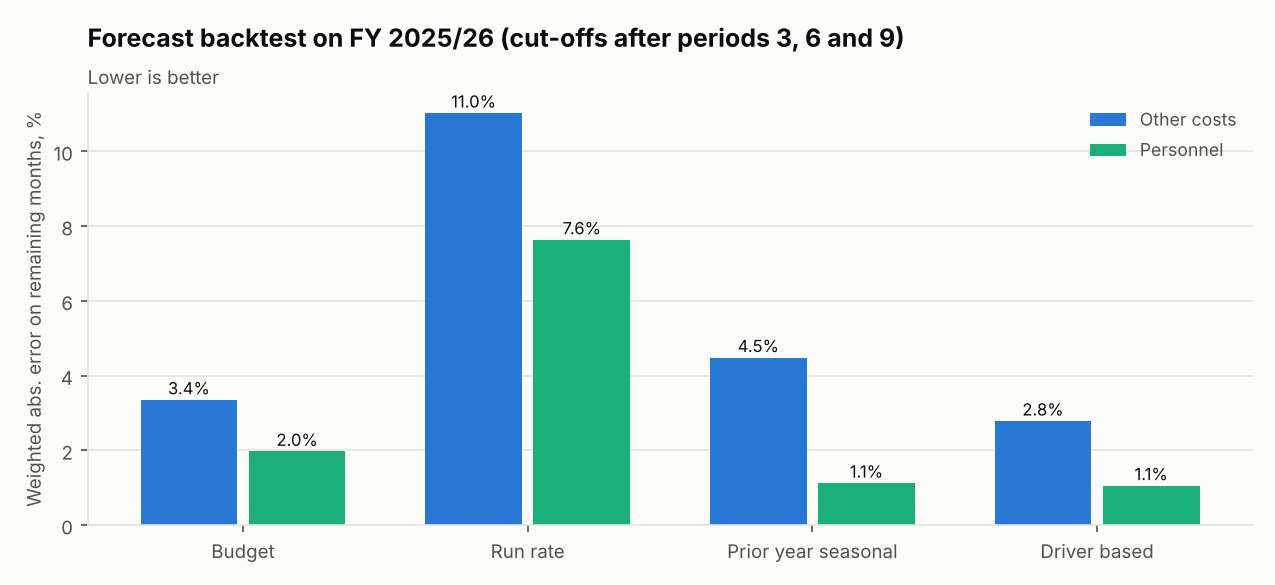

In [3]:
display(run.backtest.groupby(["functional_area", "cost_type", "method"])["wape"].mean().unstack().round(4))
display(Image(filename=str(reporting.plot_backtest(run.backtest, Path("outputs/figures/forecast_backtest.png")))))

Run rate is the worst everywhere, because it ignores the harvest peak and the November salary. The driver method wins six of the eight cells. The chosen method is never worse than the plain budget, and for selling and production costs it cuts the error by a third or more.

In [4]:
run.choice

,functional_area,cost_type,chosen_method,chosen_wape,budget_wape
0,COS,Other costs,driver,0.03,0.04
1,COS,Personnel,seasonal,0.01,0.02
2,GNA,Other costs,budget,0.02,0.02
3,GNA,Personnel,driver,0.01,0.01
4,RND,Other costs,driver,0.02,0.03
5,RND,Personnel,driver,0.01,0.01
6,SEL,Other costs,driver,0.03,0.05
7,SEL,Personnel,driver,0.01,0.03


## The 3+9 forecast

Built on September actuals after the proposed corrections from notebook 01.

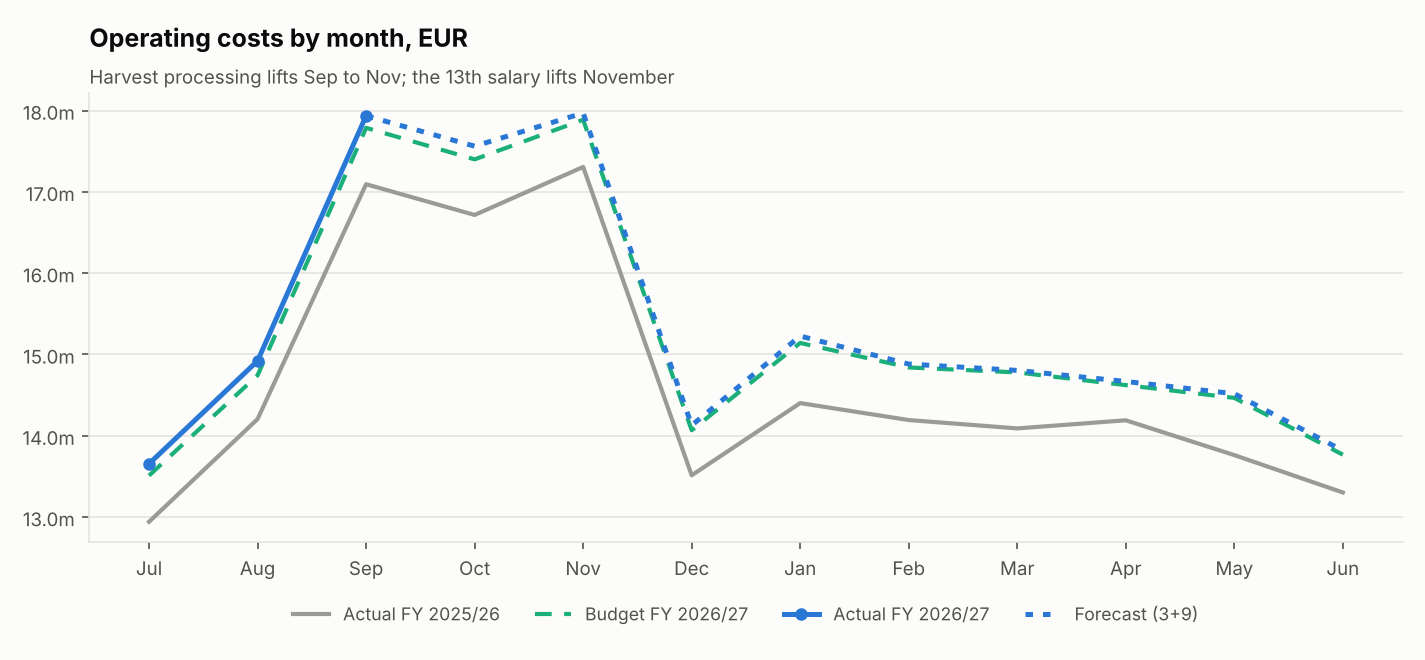

In [5]:
display(Image(filename=str(reporting.plot_cost_forecast(tables, run.cost_forecast, Path("outputs/figures/cost_forecast.png")))))

## Full-year outlook

Revenue: crops whose season is at least 15% complete carry their year-to-date volume ratio forward; the rest stay at budget volume. Price ratios carry forward for every crop that has sold. For cereals that means the autumn shortfall stays in the outlook. Corn has hardly started, so its volume stays at plan.

In [6]:
run.landing

,line,actual_ytd,forecast_rest,outlook_fy,budget_fy,prior_year_fy,var_vs_budget_eur,var_vs_budget_pct
0,Revenue,"26,364,429.00","187,617,116.00","213,981,544.00","218,849,720.00","207,113,953.00","-4,868,176.00",-0.02
1,Cost of sales,"-24,640,464.00","-67,056,137.00","-91,696,601.00","-89,828,899.00","-84,490,117.00","-1,867,703.00",-0.02
2,Selling,"-9,155,900.00","-31,465,547.00","-40,621,446.00","-40,856,807.00","-40,869,357.00","235,361.00",0.01
3,Research and development,"-9,205,578.00","-28,551,888.00","-37,757,466.00","-38,398,861.00","-36,974,782.00","641,394.00",0.02
4,General and administration,"-3,510,696.00","-10,502,884.00","-14,013,580.00","-13,928,119.00","-13,384,567.00","-85,460.00",-0.01
5,EBIT,"-20,148,209.00","50,040,660.00","29,892,451.00","35,837,034.00","31,395,130.00","-5,944,583.00",-0.17


In [7]:
land = run.landing.set_index("line")
print(f"EBIT outlook EUR {land.loc['EBIT', 'outlook_fy']/1e6:,.1f}m vs budget EUR {land.loc['EBIT', 'budget_fy']/1e6:,.1f}m "
      f"({land.loc['EBIT', 'var_vs_budget_pct']:+.1%}); margin {land.loc['EBIT', 'outlook_fy']/land.loc['Revenue', 'outlook_fy']:.1%} "
      f"vs {land.loc['EBIT', 'budget_fy']/land.loc['Revenue', 'budget_fy']:.1%} planned")

EBIT outlook EUR 29.9m vs budget EUR 35.8m (-16.6%); margin 14.0% vs 16.4% planned


## Capital projects

For each project, the estimate at completion (EAC) is spend to date plus the larger of the remaining plan and the orders already placed. The greenhouse in France has spent and ordered 116% of its approved budget, and its EAC is 23% over. That needs a budget supplement request before any further orders.

,wbs,description,approved_budget_eur,actual_to_date_eur,open_commitments_eur,eac_eur,eac_vs_budget_pct,outlook_fy_eur
0,P-25-010,Seed drying plant extension,2400000,"2,306,149.79",0.00,"2,306,150.00",-0.04,"36,633.00"
1,P-26-001,New seed processing line,4200000,"2,586,650.57","682,280.30","4,134,062.00",-0.02,"2,648,995.00"
2,P-26-002,Greenhouse complex Chartres,1800000,"1,638,785.22","449,214.78","2,215,434.00",0.23,"1,388,292.00"
3,P-26-003,Biotech lab equipment,900000,"503,020.35","254,439.12","868,989.00",-0.03,"763,365.00"
4,P-26-004,ERP S/4 upgrade,1500000,"84,096.51","206,804.86","1,461,059.00",-0.03,"1,124,516.00"


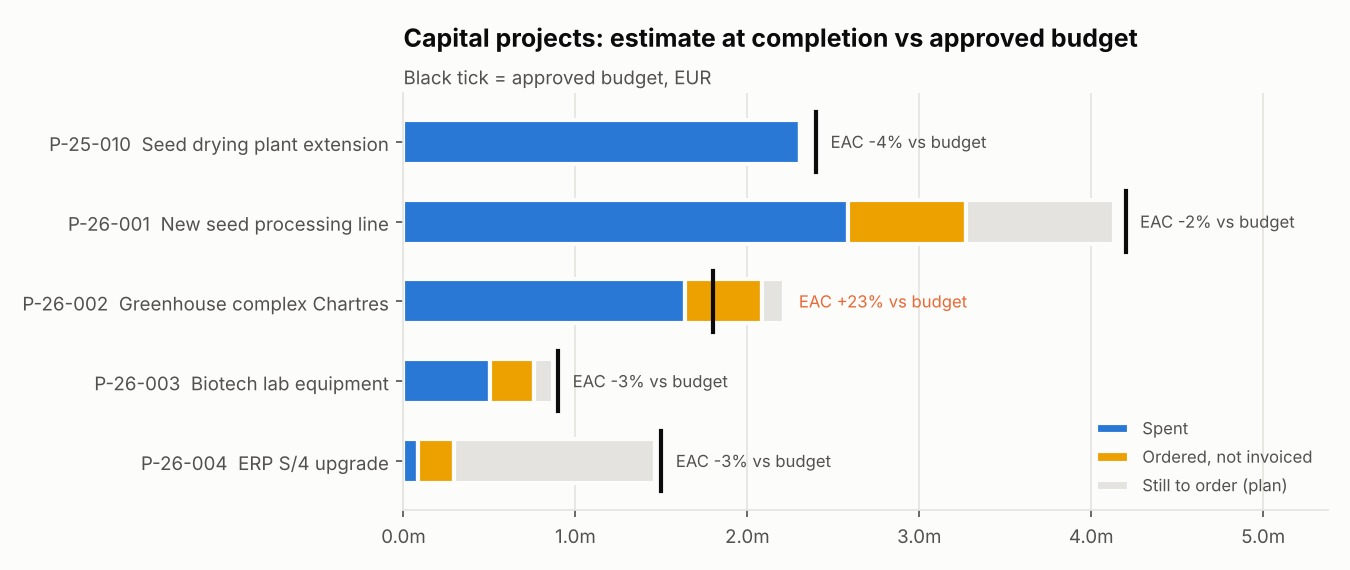

In [8]:
display(run.capex[["wbs", "description", "approved_budget_eur", "actual_to_date_eur", "open_commitments_eur", "eac_eur", "eac_vs_budget_pct", "outlook_fy_eur"]])
display(Image(filename=str(reporting.plot_capex(run.capex, Path("outputs/figures/capex_eac.png")))))

## Outputs for finance

The pipeline writes an Excel controlling pack with live formulas, a close memo in Markdown, and a star schema with DAX measures for Power BI.

In [9]:
out = pipeline.write_outputs(run)
from openpyxl import load_workbook
wb = load_workbook(out["excel"])
print("Excel sheets:", wb.sheetnames)
print("Formula examples:", wb["BvA by function"]["G2"].value, "|", wb["Outlook"]["D2"].value, "|", wb["Revenue PVM"]["H2"].value)
print("Power BI files:", [p.name for p in out["powerbi"]])

Excel sheets: ['Read me', 'Close checklist', 'Adjustments', 'BvA by function', 'Variance comments', 'Revenue PVM', 'Forecast 3+9', 'Outlook', 'Capex', 'Intercompany']
Formula examples: =E2-F2 | =B2+C2 | =(B2-C2)*E2
Power BI files: ['fact_cost.csv', 'fact_revenue.csv', 'dim_date.csv', 'dim_cost_center.csv', 'dim_account.csv', 'dim_entity.csv', 'dim_functional_area.csv']
